Example 41 shows a 1.2 GeV proton source, combined with an F8:p tally which tracks the energy distribution of pulses created in a detector. 
```
f8:h 1 
ft8 res 1 99 ! heavy-ion and residual isotopes
fq8 u e
```
This means that all energy from the entire history of the particle that gets deposited into the tally region has to be accounted for. This includes secondary particles produced during transport. 

In [1]:
%run -i clean_script.py
import openmc
import numpy as np
import math
import pathlib

In [2]:
# Material Definition
p = 'wo'
m1 = openmc.Material()
m1.add_element('Pb',1.0)
m1.set_density('g/cc',11)

materials = openmc.Materials([m1])

In [3]:
# Surface Specification
s1 = openmc.Sphere(r=100, boundary_type='vacuum')

# Cell specification
c1 = openmc.Cell(fill=m1,region=-s1)
c2 = openmc.Cell(fill=None,region=+s1)

geometry = openmc.Geometry([c1,c2])

One could in theory use the heating tally for this. For now, shown below is openmc.ParticleProductionFilter to tally any secondary particles produced during photon transport. 

In [4]:
# Tally specification
f8 = openmc.Tally()
#f8.filters = [openmc.CellFilter([c1]), openmc.EnergyFilter(np.logspace(-3,8,12,base=10)),openmc.ParticleFilter(['electron','photon'])]

f8.filters.append(openmc.ParticleProductionFilter(['electron','photon','gamma'],energies=np.logspace(4,10,7,base=10)))
#f8.filters.append(openmc.ParticleFilter(['electron','gamma']))

f8.scores = ['events']
tallies = openmc.Tallies(tallies=[f8]) 

The source specification in this case is a 1.2 GeV beam source of protons proceeding with a direction of DIR = (0,0,1) and velocity unit vector (0,0,1). 

LCA controls collision models. 
In this case,
`lca 2 1 1 23 1 1 0 -2 0` which means
* ielas 2 : means that elastic scattering is enabled for neutrons and protons
* ipreq 1 : pre-equilibrium model is used after intranuclear cascade
* iexisa 1 : use bertini model for nucleons and pions and ISABEL model for other particle types
* ichoic (00)23 : use partial pauli blocking, no interaction between excited particles above fermi sea, use Krappe's folded-Yukawa prescription for radial density, perform no reflection.refraction, with escape cutoff for isobars
* jcoul 1 :  turn on coulomb barrier
* nexite 1 : subtractn uclear recoil energy to get excitation energy 
* npidk 0 : force pion to interact by nuclear capture when cutoff is reached
* noact -2 : source particles immediately collide
* icem 0 : use the bertini or ISABEL model determined by the iexisa parameter
* ilaq : 
* nevtype : 

There is no analagous feature in OpenMC to control the nuclear interaction models. We also cannot do neutron transport. 

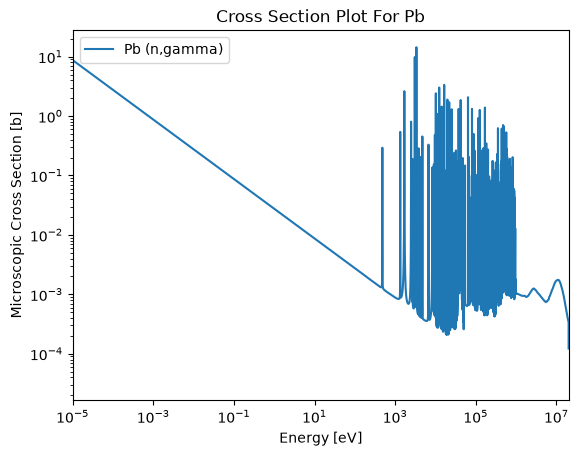

In [5]:
import matplotlib.pyplot as plt

fig = openmc.plotter.plot_xs(
    reactions = {
        'Pb': ['(n,gamma)']
    }
)
plt.show()

In [6]:
settings = openmc.Settings()
settings.run_mode='fixed source'

source = openmc.IndependentSource()
source.space = openmc.stats.Point((0,0,1))
source.angle = openmc.stats.Monodirectional((0,0,-1)) 
source.particle = 'photon'
source.energy = openmc.stats.delta_function(1e7) 

# Enable photon transport
settings.photon_transport = True 

# fluorescence photons and auger electrons enabled
settings.atomic_relaxation = True 


settings.electron_treatment = 'ttb'

settings.source = source


# History settings
settings.particles = 1000
settings.batches = 100

In [7]:
model = openmc.model.Model(geometry, materials, settings, tallies)

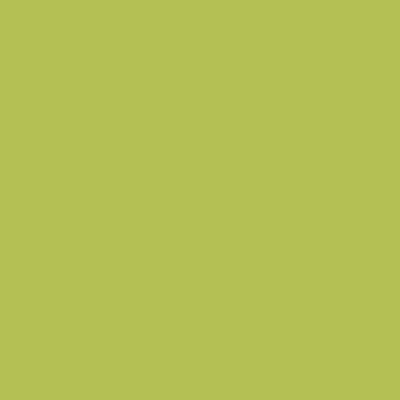

In [8]:
plots = openmc.Plots()
w = 100
origin = (0,0,0)

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)
model.export_to_xml()
openmc.plot_inline(plots)

In [9]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [11]:
with openmc.StatePoint(sp_filename) as sp:
    for key in (sp.tallies.keys()):
        print(sp.tallies)
        tally_name = sp.tallies[key].name

        results = sp.get_tally(name=tally_name)
        df = results.get_pandas_dataframe()
        df = df.loc[:,df.nunique()>1]
        #print(df)
        print(df[df['mean']>0])
        print(f"{tally_name} = {df['mean'].sum()} +/- {df['std. dev.'].sum()}\n")

{np.int32(1): Tally
	ID             =	1
	Name           =	
	Filters        =	ParticleProductionFilter
	Nuclides       =	total
	Scores         =	['events']
	Estimator      =	analog
	Multiply dens. =	True}
   particleproduction                                       mean std. dev.
             particle energy low [eV] energy high [eV]                    
12             photon         10000.0         100000.0  11.66791  0.011713
13             photon        100000.0        1000000.0   4.15313  0.005177
14             photon       1000000.0       10000000.0   0.47628  0.002018
 = 16.29732 +/- 0.01890824157761744

